In [1]:
import pandas as pd

print("--- INIZIO FASE 1: LETTURA E PREPARAZIONE DEL DATASET ---")

# 1. Estrapoliamo 1 milione di righe dal mega-database
colonne = ['AN', 'WhiteElo', 'BlackElo', 'Result']
df = pd.read_csv("chess_games.csv", usecols=colonne, nrows=1000000)

# 2. Rimuoviamo i pareggi e le righe corrotte
df = df[df['Result'] != '1/2-1/2'].copy()
df = df.dropna()

# 3. Creazione del Target e della Differenza Elo
df['Vittoria_Bianco'] = (df['Result'] == '1-0').astype(int)
df['WhiteElo'] = pd.to_numeric(df['WhiteElo'], errors='coerce')
df['BlackElo'] = pd.to_numeric(df['BlackElo'], errors='coerce')
df = df.dropna()
df['Differenza_Elo'] = df['WhiteElo'] - df['BlackElo']

# 4. Filtro per le partite arrivate almeno alla mossa 20 (40 ply)
df['numero_mezze_mosse'] = df['AN'].apply(lambda x: len(str(x).split()))
df_filtrato = df[df['numero_mezze_mosse'] >= 40].copy()

# 5. PRECAUZIONE TEMPI DI CALCOLO
# Campioniamo per l'estrazione per evitare crash di memoria o tempi infiniti.
# Se vuoi elaborare un intero milione di partite, cambia N_MAX a 1000000
N_MAX = 1000000
n_campioni = min(N_MAX, len(df_filtrato))
df_finale = df_filtrato[['AN', 'Differenza_Elo', 'Vittoria_Bianco']].sample(n=n_campioni, random_state=42)

print(f"Partite filtrate, pulite e pronte per l'estrazione: {len(df_finale)}")
print("\n--- ANTEPRIMA DATI ---")
print(df_finale.head())

--- INIZIO FASE 1: LETTURA E PREPARAZIONE DEL DATASET ---
Partite filtrate, pulite e pronte per l'estrazione: 895684

--- ANTEPRIMA DATI ---
                                                       AN  Differenza_Elo  \
967923  1. d4 Nf6 2. Nf3 c5 3. c4 cxd4 4. Nxd4 Nc6 5. ...             108   
403328  1. e4 d5 2. exd5 c6 3. Nc3 cxd5 4. Nf3 Nc6 5. ...             112   
527906  1. d4 d5 2. Bf4 Nf6 3. e3 e6 4. Nf3 c5 5. c3 N...             104   
293778  1. e4 c5 2. d3 Nc6 3. Nc3 d6 4. Nf3 Nf6 5. Nd5...             -60   
648812  1. e4 e5 2. Bc4 d6 3. h3 h6 4. Nf3 Nf6 5. d3 a...              53   

        Vittoria_Bianco  
967923                0  
403328                1  
527906                1  
293778                0  
648812                1  


In [2]:

import pandas as pd
import chess
import re
from tqdm import tqdm

print("--- INIZIO FASE 2: ESTRAZIONE MATEMATICA E TRADUZIONE ---")
tqdm.pandas(desc=" Estrazione coordinate in corso...")

pezzi_standard = {
    'P': 8, 'N': 2, 'B': 2, 'R': 2, 'Q': 1, 'K': 1,
    'p': 8, 'n': 2, 'b': 2, 'r': 2, 'q': 1, 'k': 1
}

def estrai_coordinate(mosse_str):
    board = chess.Board()
    
    # TRADUZIONE PGN -> SAN: Rimuoviamo i numeri di mossa (es. "1.", "2.", "3.")
    # In questo modo la libreria 'chess' potrà leggere le mosse senza bloccarsi.
    mosse_pulite = re.sub(r'\d+\.', ' ', str(mosse_str))
    mosse = mosse_pulite.split()
    
    for mossa in mosse[:40]:
        try:
            board.push_san(mossa)
        except:
            break
            
    trovati = {pezzo: 0 for pezzo in pezzi_standard.keys()}
    coord_dict = {}
    
    for square in chess.SQUARES:
        pezzo = board.piece_at(square)
        if pezzo:
            simbolo = pezzo.symbol()
            trovati[simbolo] += 1
            indice = trovati[simbolo]
            
            x = chess.square_file(square) + 1
            y = chess.square_rank(square) + 1
            
            coord_dict[f"{simbolo}_{indice}_X"] = x
            coord_dict[f"{simbolo}_{indice}_Y"] = y
            
    for simbolo, max_count in pezzi_standard.items():
        count_trovati = trovati[simbolo]
        for i in range(count_trovati + 1, max_count + 1):
            coord_dict[f"{simbolo}_{i}_X"] = 0
            coord_dict[f"{simbolo}_{i}_Y"] = 0
            
    return coord_dict

print("Inizio dell'elaborazione delle posizioni.")

lista_dizionari = df_finale['AN'].progress_apply(estrai_coordinate).tolist()

df_coordinate = pd.DataFrame(lista_dizionari)
df_finale = df_finale.reset_index(drop=True)
df_ml = pd.concat([df_finale[['Differenza_Elo', 'Vittoria_Bianco']], df_coordinate], axis=1)

print("\n Matrice per il Machine Learning creata con successo!")
print(f" Dimensioni Matrice: {df_ml.shape[0]} righe e {df_ml.shape[1]} colonne (incluse eventuali promozioni).")

--- INIZIO FASE 2: ESTRAZIONE MATEMATICA E TRADUZIONE ---
Inizio dell'elaborazione delle posizioni.


 Estrazione coordinate in corso...: 100%|██████████| 895684/895684 [13:25<00:00, 1112.26it/s]



 Matrice per il Machine Learning creata con successo!
 Dimensioni Matrice: 895684 righe e 80 colonne (incluse eventuali promozioni).


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("--- INIZIO FASE 3: PREPARAZIONE DATI (TRAIN/TEST SPLIT E SCALER) ---")

# 1. Riempimento dei valori nulli
df_ml = df_ml.fillna(0)

# 2. Separazione delle Features (X) dal Target (y)
X = df_ml.drop(columns=['Vittoria_Bianco'])
y = df_ml['Vittoria_Bianco']

# 3. Split: 80% Addestramento (Train) e 20% Validazione (Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Rimozione delle colonne quasi sempre nulle (contate sul solo training set)
SOGLIA = 100
nonzero = (X_train != 0).sum()
rare = nonzero[nonzero < SOGLIA].index
X_train = X_train.drop(columns=rare)
X_test = X_test.drop(columns=rare)
print(f"Colonne rimosse ({len(rare)}): {list(rare)}")
print(f"Feature rimaste: n = {X_train.shape[1]}")

# 5. Standardizzazione
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f" Partite assegnate all'Addestramento (Train): {len(X_train)}")
print(f" Partite assegnate alla Validazione (Test): {len(X_test)}")

--- INIZIO FASE 3: PREPARAZIONE DATI (TRAIN/TEST SPLIT E SCALER) ---
Colonne rimosse (10): ['r_3_X', 'r_3_Y', 'R_3_X', 'R_3_Y', 'Q_3_X', 'Q_3_Y', 'N_3_X', 'N_3_Y', 'n_3_X', 'n_3_Y']
Feature rimaste: n = 69
 Partite assegnate all'Addestramento (Train): 716547
 Partite assegnate alla Validazione (Test): 179137


In [4]:
import time
from sklearn.linear_model import LogisticRegression

print("--- INIZIO FASE 4: ADDESTRAMENTO E CONFRONTO OTTIMIZZATORI ---")

# =====================================================================
# MODELLO A: Variate dello Steepest Descent (SAGA)
# Utilizza solo il Gradiente (derivata prima)
# =====================================================================
print("\n1. Addestramento Modello A (Solver: SAGA / Steepest Descent)...")
modello_saga = LogisticRegression(solver='saga', max_iter=2000, random_state=42)

start_time_saga = time.time()
modello_saga.fit(X_train_scaled, y_train)
end_time_saga = time.time()

tempo_saga = end_time_saga - start_time_saga
iterazioni_saga = modello_saga.n_iter_[0]

print(f"✅ SAGA completato in {tempo_saga:.3f} secondi.")
print(f"👣 Iterazioni (passi) necessari: {iterazioni_saga}")


# =====================================================================
# MODELLO B: Metodo Quasi-Newton (L-BFGS)
# Approssima la matrice Hessiana (derivata seconda)
# =====================================================================
print("\n2. Addestramento Modello B (Solver: L-BFGS / Quasi-Newton)...")
modello_lbfgs = LogisticRegression(solver='lbfgs', max_iter=2000, random_state=42)

start_time_lbfgs = time.time()
modello_lbfgs.fit(X_train_scaled, y_train)
end_time_lbfgs = time.time()

tempo_lbfgs = end_time_lbfgs - start_time_lbfgs
iterazioni_lbfgs = modello_lbfgs.n_iter_[0]

print(f"✅ L-BFGS completato in {tempo_lbfgs:.3f} secondi.")
print(f"👣 Iterazioni (passi) necessari: {iterazioni_lbfgs}")

print("\n--- ADDESTRAMENTO COMPLETATO ---")

--- INIZIO FASE 4: ADDESTRAMENTO E CONFRONTO OTTIMIZZATORI ---

1. Addestramento Modello A (Solver: SAGA / Steepest Descent)...
✅ SAGA completato in 47.743 secondi.
👣 Iterazioni (passi) necessari: 72

2. Addestramento Modello B (Solver: L-BFGS / Quasi-Newton)...
✅ L-BFGS completato in 4.127 secondi.
👣 Iterazioni (passi) necessari: 38

--- ADDESTRAMENTO COMPLETATO ---


--- INIZIO FASE 5: ANALISI DELLA CONVERGENZA ---


C:\Users\utente\AppData\Local\Temp\ipykernel_25996\1540959788.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelli, y=tempi, ax=ax[0], palette=['#3498db', '#2ecc71'])
C:\Users\utente\AppData\Local\Temp\ipykernel_25996\1540959788.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=modelli, y=iterazioni, ax=ax[1], palette=['#e74c3c', '#f1c40f'])


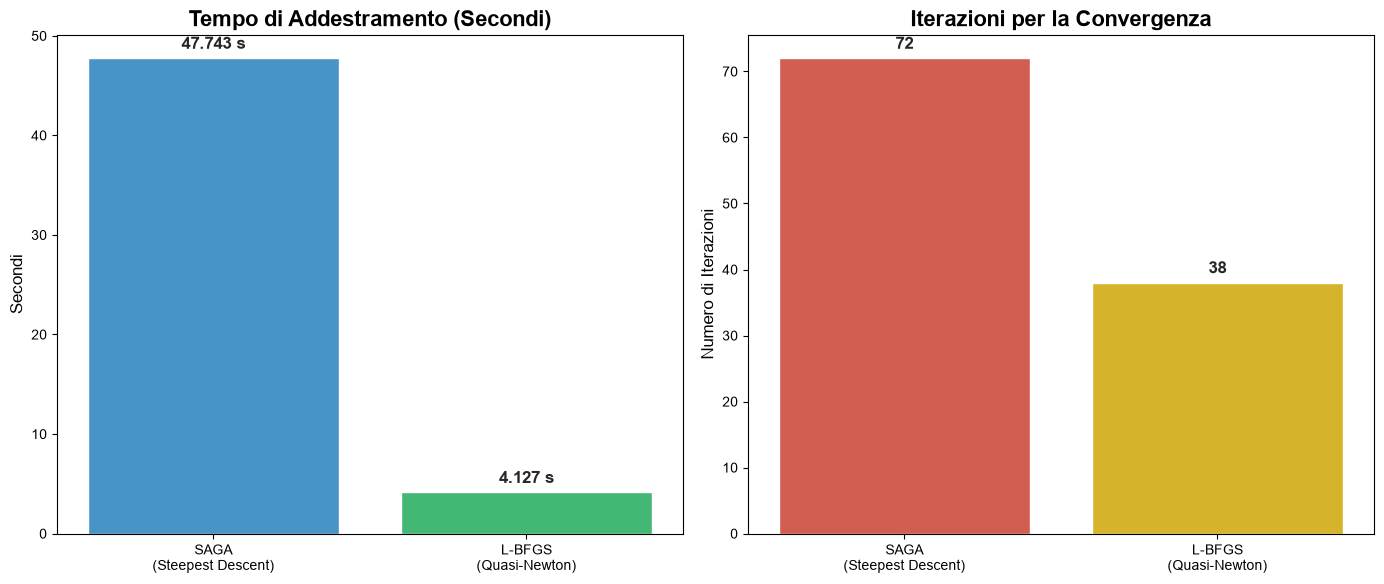

--- ANALISI DELLA CONVERGENZA COMPLETATA ---


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- INIZIO FASE 5: ANALISI DELLA CONVERGENZA ---")

# 1. Prepariamo i dati da plottare
modelli = ['SAGA\n(Steepest Descent)', 'L-BFGS\n(Quasi-Newton)']
tempi = [tempo_saga, tempo_lbfgs]
iterazioni = [iterazioni_saga, iterazioni_lbfgs]

# 2. Impostazione della figura con due grafici affiancati
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.set_theme(style="whitegrid")

# --- Grafico 1: Tempo di Addestramento ---
sns.barplot(x=modelli, y=tempi, ax=ax[0], palette=['#3498db', '#2ecc71'])
ax[0].set_title('Tempo di Addestramento (Secondi)', fontsize=16, fontweight='bold')
ax[0].set_ylabel('Secondi', fontsize=12)

# Aggiungiamo le etichette con il valore esatto sopra le barre
for i, v in enumerate(tempi):
    ax[0].text(i, v + (max(tempi)*0.02), f"{v:.3f} s", ha='center', fontsize=12, fontweight='bold')

# --- Grafico 2: Numero di Iterazioni ---
sns.barplot(x=modelli, y=iterazioni, ax=ax[1], palette=['#e74c3c', '#f1c40f'])
ax[1].set_title('Iterazioni per la Convergenza', fontsize=16, fontweight='bold')
ax[1].set_ylabel('Numero di Iterazioni', fontsize=12)

for i, v in enumerate(iterazioni):
    ax[1].text(i, v + (max(iterazioni)*0.02), str(v), ha='center', fontsize=12, fontweight='bold')

# 3. Mostriamo il capolavoro
plt.tight_layout()
plt.show()

print("--- ANALISI DELLA CONVERGENZA COMPLETATA ---")

--- INIZIO FASE 6: VALUTAZIONE DELLE PERFORMANCE ---

Confronto Previsioni: I due modelli hanno dato la stessa risposta nel 99.88% dei casi!
Questo dimostra che entrambi i solver sono conversi allo stesso minimo globale della funzione convessa.

--- CLASSIFICATION REPORT (Modello L-BFGS) ---
                     precision    recall  f1-score   support

  Vittoria Nero (0)       0.68      0.68      0.68     87632
Vittoria Bianco (1)       0.69      0.70      0.70     91505

           accuracy                           0.69    179137
          macro avg       0.69      0.69      0.69    179137
       weighted avg       0.69      0.69      0.69    179137


Generazione della Matrice di Confusione in corso...


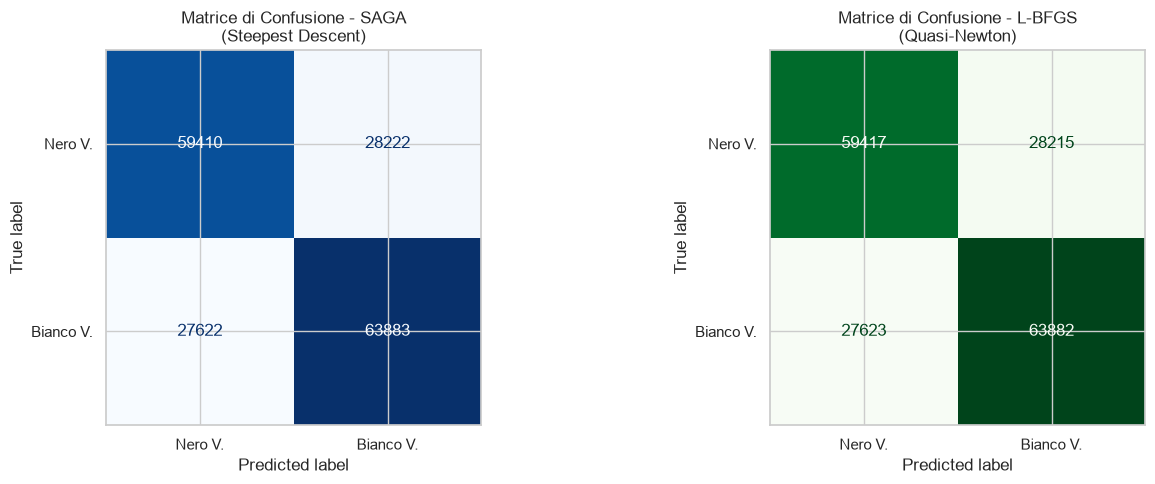

--- VALUTAZIONE COMPLETATA ---


In [6]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- INIZIO FASE 6: VALUTAZIONE DELLE PERFORMANCE ---")

# 1. Generiamo le previsioni sui dati di Test (il 20% che il modello non ha mai visto)
y_pred_saga = modello_saga.predict(X_test_scaled)
y_pred_lbfgs = modello_lbfgs.predict(X_test_scaled)

# 2. Rispondiamo alla domanda di Navid: le previsioni sono diverse?
previsioni_uguali = (y_pred_saga == y_pred_lbfgs).sum()
totale_test = len(y_test)
percentuale_uguaglianza = (previsioni_uguali / totale_test) * 100

print(f"\nConfronto Previsioni: I due modelli hanno dato la stessa risposta nel {percentuale_uguaglianza:.2f}% dei casi!")
print("Questo dimostra che entrambi i solver sono conversi allo stesso minimo globale della funzione convessa.")

# 3. Metriche Classiche (Usiamo i risultati di L-BFGS, visto che sono uguali)
print("\n--- CLASSIFICATION REPORT (Modello L-BFGS) ---")
print(classification_report(y_test, y_pred_lbfgs, target_names=['Vittoria Nero (0)', 'Vittoria Bianco (1)']))

# 4. Matrici di Confusione
print("\nGenerazione della Matrice di Confusione in corso...")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot Matrice SAGA
cm_saga = confusion_matrix(y_test, y_pred_saga)
disp_saga = ConfusionMatrixDisplay(confusion_matrix=cm_saga, display_labels=['Nero V.', 'Bianco V.'])
disp_saga.plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Matrice di Confusione - SAGA\n(Steepest Descent)')

# Plot Matrice L-BFGS
cm_lbfgs = confusion_matrix(y_test, y_pred_lbfgs)
disp_lbfgs = ConfusionMatrixDisplay(confusion_matrix=cm_lbfgs, display_labels=['Nero V.', 'Bianco V.'])
disp_lbfgs.plot(ax=ax[1], cmap='Greens', colorbar=False)
ax[1].set_title('Matrice di Confusione - L-BFGS\n(Quasi-Newton)')

plt.tight_layout()
plt.show()

print("--- VALUTAZIONE COMPLETATA ---")

--- STIMA DEL PUNTO DI CROSSOVER (FLOPs) ---
kappa efficace = 3.765e+06


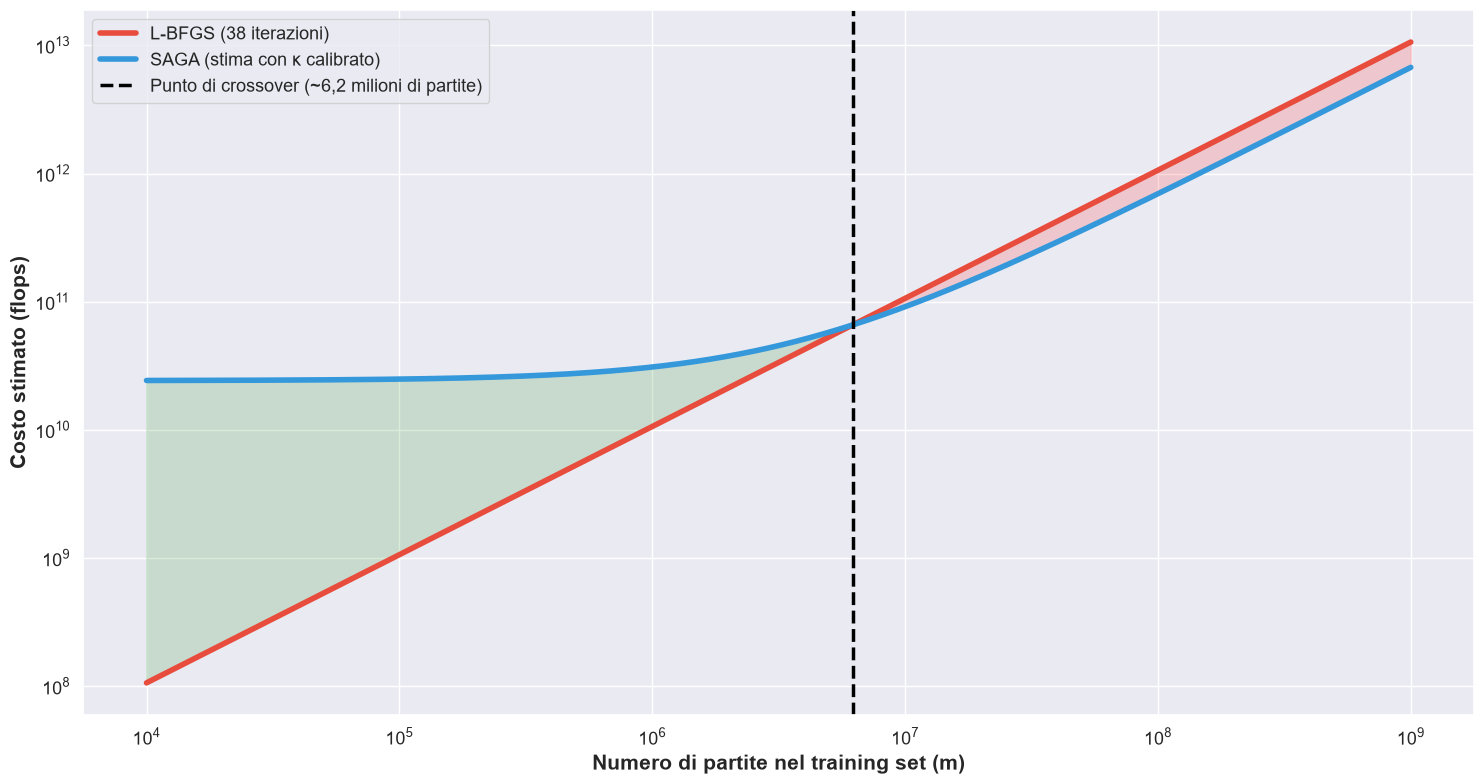

Numero di partite al punto di crossover: 6,203,144
Grafico salvato in: crossover.pdf


In [9]:
# =====================================================================
# CELLA EXTRA: GRAFICO DEL CROSSOVER (MODELLO TEORICO DEI COSTI)
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- STIMA DEL PUNTO DI CROSSOVER (FLOPs) ---")

# 1. PARAMETRI MISURATI SUL PROBLEMA
m_train = X_train_scaled.shape[0]          # 716.547 partite di training
d = X_train_scaled.shape[1] + 1            # n + 1 = 70 (feature + intercetta)
I_lbfgs = iterazioni_lbfgs                 # 38 iterazioni osservate
E_saga_oss = iterazioni_saga               # 72 epoche osservate

epsilon = 1e-5
ln_eps = np.log(1 / epsilon)               # ≈ 11.51

# kappa "efficace": calibrato in modo che la stima (1 + kappa/m) ln(1/eps)
# riproduca le epoche osservate di SAGA sul dataset attuale
kappa = m_train * (E_saga_oss / ln_eps - 1)
print(f"kappa efficace = {kappa:.3e}")

# 2. COSTI (Cap. 3): L-BFGS ≈ 4 m (n+1) per iterazione,
#    SAGA ≈ 8 m (n+1) per epoca + 4 m (n+1) di inizializzazione.
#    Ipotesi: lambda fisso, quindi kappa non dipende da N.
N = np.logspace(4, 9, 2000)
costo_lbfgs = I_lbfgs * 4 * N * d
epoche_saga = (1 + kappa / N) * ln_eps
costo_saga = 4 * N * d + epoche_saga * 8 * N * d

# 3. PUNTO DI CROSSOVER (soluzione esatta dell'uguaglianza dei costi)
#    4 I = 4 + 8 (1 + kappa/N) ln(1/eps)  =>  N* = kappa / ((I - 1)/(2 ln(1/eps)) - 1)
den = (I_lbfgs - 1) / (2 * ln_eps) - 1
if den <= 0:
    raise ValueError("Nessun crossover: L-BFGS converge in troppo poche iterazioni.")
crossover_N = kappa / den

# 4. GRAFICO (versione per la tesi)
plt.figure(figsize=(15, 8))
sns.set_theme(style="darkgrid")

plt.plot(N, costo_lbfgs, label=f"L-BFGS ({I_lbfgs} iterazioni)", color="#e74c3c", linewidth=4)
plt.plot(N, costo_saga, label="SAGA (stima con κ calibrato)", color="#3498db", linewidth=4)
plt.axvline(x=crossover_N, color='black', linestyle='--', linewidth=2.5,
            label=f"Punto di crossover (~{crossover_N/1e6:.1f} milioni di partite)".replace('.', ','))

plt.fill_between(N, costo_saga, costo_lbfgs, where=(N > crossover_N), color='red', alpha=0.15)
plt.fill_between(N, costo_lbfgs, costo_saga, where=(N < crossover_N), color='green', alpha=0.15)

ax = plt.gca()
ax.set_xscale('log')
ax.set_yscale('log')
ax.tick_params(labelsize=13)

plt.xlabel("Numero di partite nel training set (m)", fontsize=15, fontweight='bold')
plt.ylabel("Costo stimato (flops)", fontsize=15, fontweight='bold')
plt.legend(fontsize=13, loc='upper left')
plt.tight_layout()

# Salvataggio in PDF (vettoriale) per l'inserimento in LaTeX
plt.savefig("crossover.pdf", bbox_inches="tight")
plt.show()

print(f"Numero di partite al punto di crossover: {crossover_N:,.0f}")
print("Grafico salvato in: crossover.pdf")

In [8]:
# =====================================================================
# CELLA EXTRA: CONDIZIONAMENTO DELLA MATRICE E SALVATAGGIO DATI PER MATLAB
# =====================================================================
import numpy as np
from scipy.io import savemat

theta = np.r_[modello_lbfgs.intercept_, modello_lbfgs.coef_.ravel()]  # [theta_0; w]
savemat("dati_condizionamento.mat",
        {"X": np.asarray(X_train_scaled), "theta": theta, "C": modello_lbfgs.C},
        do_compression=True)